$$\frac{\partial^2 u}{\partial t^2} = \frac{\partial^2 u}{\partial x^2} - \sin(u) \quad ; -2 \le x \le 2$$

Initial Conditions
$$u(x, 0) = g(x) = 0,$$

$$u_t(x, 0) = h(x) = 4\operatorname{sech}(x)$$

with the boundary conditions

$$h_1(t) = u(-2,t) = 4 \arctan(t\operatorname{sech}(-2)), \quad h_2(t) = u(2,t) = 4 \arctan(t\operatorname{sech}(2)).$$

The analytical solution is given in $[13]$ as

$$u(x,t) = 4 \arctan(\operatorname{sech}(x)t).$$

In [1]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
from SG_solver import rbf_matrix, second_divided_difference, d2_L_W2, paper_rms
from fractal_SG_solver import ddphi, H5_dd, d2_fractal_L_W2
from alpha_fractal_function import alpha_fractalize_second_derivative

In [2]:
# Paper Example 2 parameters.
a = -2.0
b = 2.0
#######################
K = 10
s = 1.0
h = 0.01
tau = 0.01
c = 0.1 * (h**(1.0 / 3.0))
################
T = 1.0
###################

$$x_i = a + \frac{i(b-a)}{n}, \quad i = 0, \ldots, n,$$

and $N = \frac{n}{K}$ , where K is a positive integer. The choice of
the interpolation centers $\{x_{k_j}\}_{j=1}^N$ as follows

$$x_{k_1} = x_1, \quad x_{k_N} = x_{n-1},$$

$$x_{k_j} = a + \frac{(j-1)(b-a)}{N}, \quad j = 2, \dots, N-1.$$

In [3]:
n = (b - a) / h

if n != int(n):
    raise ValueError("h must divide b-a exactly.")

n = int(n)

if n % K != 0:
    raise ValueError("n must be divisible by K because the paper defines N = n / K.")

N = n // K
Nt = int(round(T / tau))

x = np.linspace(a, b, n + 1)

# Interpolation center indices k_j, j = 1,...,N
k_idx = np.concatenate(([1], K * np.arange(1, N - 1), [n - 1])).astype(int)

xk = x[k_idx]
xkj = []
for j in range(1, N + 1):
    if j == 1:
        value = float(x[1])
        xkj.append(value)

    elif 1 < j < N:
        value = a + ((j - 1) * (b - a)) / N
        xkj.append(value)
    elif j == N:
        value = float(x[n - 1])
        xkj.append(value)

The analytical solution is given in $[13]$ as

$$u(x,t) = 4 \arctan(\operatorname{sech}(x)t).$$

In [4]:
def exact_u(x, t):
    return 4.0 * np.arctan((1.0 / np.cosh(x)) * t)

At $t=0$, 
$$u(x,0) = g(x) = 0,$$
$$u_t(x,0) = h(x) = 4\operatorname{sech}(x).$$

In [5]:
# Storage for time and space levels
# U[d, i] ≈ u(x_i, d*tau), d=0,...,Nt

U = np.zeros((Nt + 2, len(x)))
print(np.shape(U))

# Initial condition at t=0
U[0, :] = exact_u(x, 0.0)

(102, 401)


The boundary conditions

$$u(-2,t) = 4 \arctan(t\operatorname{sech}(-2)), \quad u(2,t) = 4 \arctan(t\operatorname{sech}(2)).$$

In [6]:
U[0, 0]  = exact_u(x[0], 0.0)
U[0, -1] = exact_u(x[-1], 0.0)

$$
\sum_{j=1}^{N} \alpha_j \varphi(|x_{k_i}-x_{k_j}|) =
\frac{2u_{k_i+1}^{n}}{(x_{k_i+1}-x_{k_i})(x_{k_i+1}-x_{k_i-1})}
+ \frac{2u_{k_i-1}^{n}}{(x_{k_i}-x_{k_i-1})(x_{k_i+1}-x_{k_i-1})}
- \frac{2u_{k_i}^{n}}{(x_{k_i}-x_{k_i-1})(x_{k_i+1}-x_{k_i})}.
\tag{19}$$

The right side is the same three-point second divided-difference formula from Eq. 15, and applied at the current time-level values $u_n$.
$$ \alpha_m = \sum_{i=1}^{N}\left[A^{-1}\right]_{mi}\left(\frac{2u_{k_i+1}^{n}}{(x_{k_i+1}-x_{k_i})(x_{k_i+1}-x_{k_i-1})} + \frac{2u_{k_i-1}^{n}}{(x_{k_i}-x_{k_i-1})(x_{k_i+1}-x_{k_i-1})} - \frac{2u_{k_i}^{n}}{(x_{k_i}-x_{k_i-1})(x_{k_i+1}-x_{k_i})} \right),\\ \quad m=1,\ldots,N,$$
$$A_{ij}=\varphi(|x_{k_i}-x_{k_j}|)$$

In [7]:
# Build approximation of u_xx at t=0
A0 = rbf_matrix(xk, s)
rhs0 = []
for kj in k_idx:
    rhs0.append(second_divided_difference(x, U[0, :], kj))
rhs0 = np.asarray(rhs0)

alpha0 = np.linalg.solve(A0, rhs0)

# print("alpha0:", alpha0)

$$u_{k}^{n+1} = 2u_{k}^{n} - u_{k}^{n-1} - \tau^{2} \sin(u_{k}^{n}) + \tau^{2} \left[ \sum_{j=1}^{N} \alpha_{j} \varphi(x_{k} - x_{k_{j}}) + \sum_{i=0}^{n} \left( u_{i}^{n} - \sum_{j=1}^{N} \alpha_{j} \sqrt{s^{2} + (x_{i} - x_{k_{j}})^{2}} \right) \psi_{i}''(x_{k}) \right], \tag{18}$$
$$u_{k}^{n+1} = 2u_{k}^{n} - u_{k}^{n-1} - \tau^{2} \sin(u_{k}^{n}) + \tau^{2}*\left(L_{w_{2}}u_{k}^{n}\right)''$$

Given initial conditions: 
$$u(x, 0) = g(x) = 0, \quad u_t(x, 0) = h(x) = 4\operatorname{sech}(x)$$
Using Central Difference:
$$\frac{u_{k}^{1} - u_{k}^{-1}}{2\tau} = h(x_k) \implies u_{k}^{-1} = u_{k}^{1} - 2\tau h(x_k)$$
We have
$$u_{k}^{1} = u_{k}^{0} + \tau h(x_k) + \frac{1}{2}*\tau^{2}*\left[\left(L_{w_{2}}u_{k}^{0}\right)'' - \sin(u_{k}^{0})\right]$$

In [8]:
# for 1st time step
uxx0 = np.zeros(len(x))
for i in range(len(x)):
    uxx0[i] = d2_L_W2(i, x, U[0, :], xk, alpha0, s, c)

# Since u(x, 0) = 0 and u_t(x, 0) = h(x) = 4*sech(x)
U[1, :] = U[0, :] + tau * (4.0 / np.cosh(x)) + 0.5 * tau**2 * (uxx0 - np.sin(U[0, :]))

In [9]:
# Time stepping:
# u_k^{n+1} = 2u_k^n - u_k^{n-1} + tau^2 * (L_w2 u_k^d)'' - tau^2 * sin(u_k^d)
#-------------------------------------------------------------

A = rbf_matrix(xk, s)
for d in tqdm(range(1, Nt + 1), desc="Time stepping", unit="step"):
    rhs_d = np.asarray([second_divided_difference(x, U[d], kj) for kj in k_idx])
    alpha1 = np.linalg.solve(A, rhs_d)

    uxx = np.zeros(len(x))
    for i in range(len(x)):
        uxx[i] = d2_L_W2(i, x, U[d], xk, alpha1, s, c)

    U[d + 1, :] = 2.0 * U[d, :] - U[d - 1, :] + tau**2 * uxx - tau**2 * np.sin(U[d, :])

Time stepping: 100%|██████████| 100/100 [01:40<00:00,  1.00s/step]


In [10]:
f_alpha = [0.0005, -0.002, -0.001, -0.001, -0.002, 0.0005]
n_subintervals =  len(f_alpha)
n_iter = 6
X = np.linspace(a, b, n_subintervals + 1)
fractal_dd = alpha_fractalize_second_derivative(
    lambda z: ddphi(z, c=c),
    lambda z: H5_dd(z, x1=a - b, xN=b - a, c=c),
    a - b,
    b - a,
    n_subintervals,
    f_alpha,
    n_iter,
)

In [11]:
# Initial condition at t=0
f_U = np.zeros((Nt + 2, len(x)))
print(np.shape(f_U))
f_U[0, :] = exact_u(x, 0.0)  # initial condition at t=0

f_U[0, 0]  = exact_u(x[0], 0.0)
f_U[0, -1] = exact_u(x[-1], 0.0)

f_uxx0 = np.zeros(len(x))
for i in range(len(x)):
    f_uxx0[i] = d2_fractal_L_W2(i, x, f_U[0, :], xk, alpha0, s, fractal_dd)

# Since u(x, 0) = 0 and u_t(x, 0) = h(x) = 4*sech(x)
f_U[1, :] = f_U[0, :] + tau * (4.0 / np.cosh(x)) + 0.5 * tau**2 * (f_uxx0 - np.sin(f_U[0, :]))

(102, 401)


In [12]:
# Time stepping:
# u_k^{n+1} = 2u_k^n - u_k^{n-1} + tau^2 * (L_w2 u_k^d)'' - tau^2 * sin(u_k^d)
# using d instead of n for time level index to avoid confusion with spatial index k.
A = rbf_matrix(xk, s)
for d in tqdm(range(1, Nt + 1), desc="Time stepping", unit="step"):
    rhs_d = np.asarray([second_divided_difference(x, f_U[d], kj) for kj in k_idx])
    alpha2 = np.linalg.solve(A, rhs_d)

    f_uxx = np.zeros(len(x))
    for i in range(len(x)):
        f_uxx[i] = d2_fractal_L_W2(i, x, f_U[d], xk, alpha2, s, fractal_dd)

    f_U[d + 1, :] = 2.0 * f_U[d, :] - f_U[d - 1, :] + tau**2 * f_uxx - tau**2 * np.sin(f_U[d, :])

Time stepping: 100%|██████████| 100/100 [07:48<00:00,  4.68s/step]


In [13]:
# Final solution and error at time T
u_num = U[Nt, :]
f_u_num = f_U[Nt, :]
u_ex = exact_u(x, T)

err = -(u_ex - u_num)
f_err = -(u_ex - f_u_num)

abs_err = np.abs(err)
f_abs_err = np.abs(f_err)

Linf = np.max(abs_err)
f_Linf = np.max(f_abs_err)

RMS = np.sqrt(np.mean(abs_err**2))
f_RMS = np.sqrt(np.mean(f_abs_err**2))

paper_RMS = paper_rms(u_ex, u_num)
f_paper_RMS = paper_rms(u_ex, f_u_num)

Linf_difference = Linf - f_Linf
RMS_difference = RMS - f_RMS

print("Linf error =", Linf)
print("f_Linf error =", f_Linf)
print("RMS error  =", RMS)
print("f_RMS error  =", f_RMS)
print("Paper RMS error =", paper_RMS)
print("f_Paper RMS error =", f_paper_RMS)
print("Linf difference =", Linf_difference)
print("RMS difference =", RMS_difference)

Linf error = 0.0021602836781873247
f_Linf error = 0.28445855392783526
RMS error  = 0.00038858732113713823
f_RMS error  = 0.028649038954363163
Paper RMS error = 1.9405124792199647e-05
f_Paper RMS error = 0.0014306647331136346
Linf difference = -0.28229827024964793
RMS difference = -0.028260451633226026


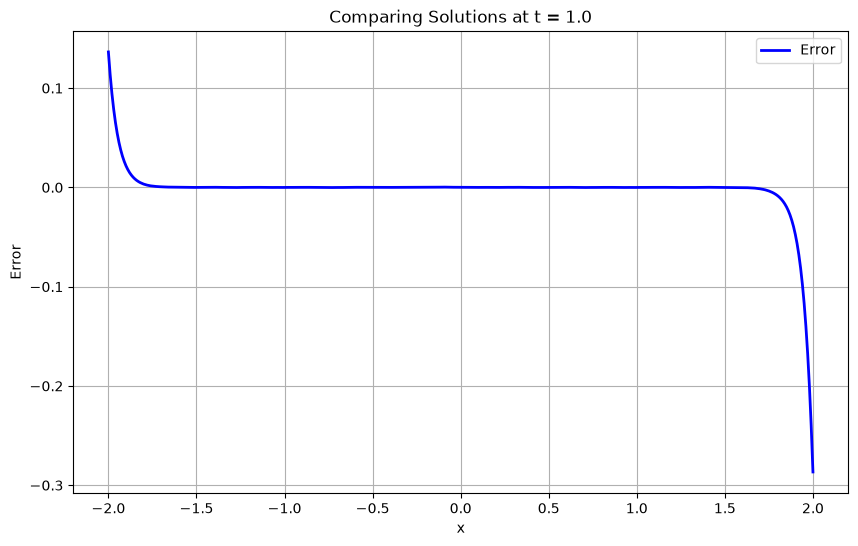

In [14]:
comp_error = u_num - f_u_num
plt.figure(figsize=(10, 6))
plt.plot(x, comp_error, label="Error", color="blue", linewidth=2)
plt.xlabel("x")
plt.ylabel("Error")
plt.title(f"Comparing Solutions at t = {T}")
plt.grid(True)
plt.legend()
plt.show()

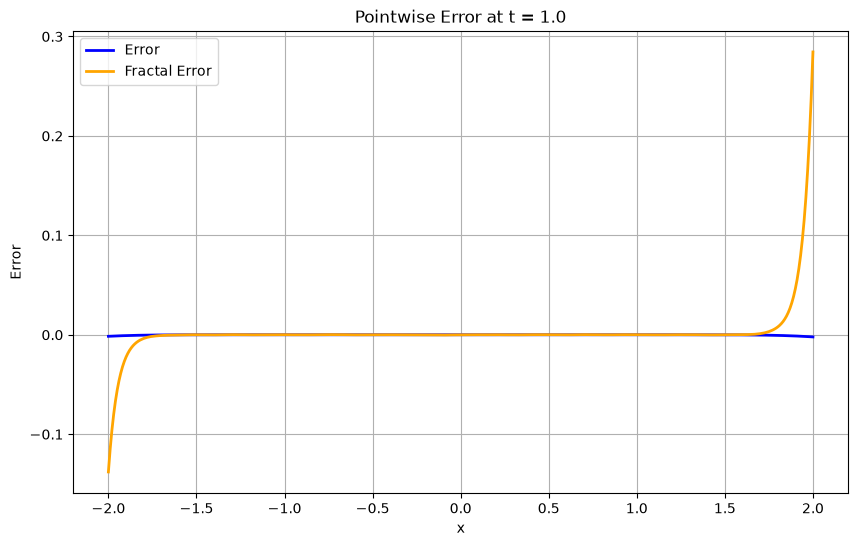

In [15]:
plt.figure(figsize=(10, 6))
plt.plot(x, err, label="Error", color="blue", linewidth=2)
plt.plot(x, f_err, label="Fractal Error", color="orange", linewidth=2)
plt.xlabel("x")
plt.ylabel("Error")
plt.title(f"Pointwise Error at t = {T}")
plt.grid(True)
plt.legend()
plt.savefig("Error_Comparison_SG_equation_eg2.png", format="png")
plt.show()

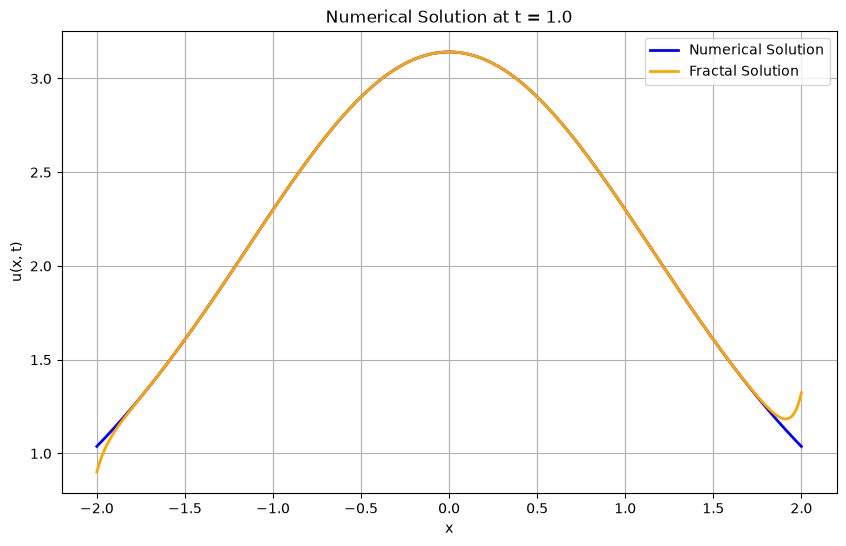

In [16]:
plt.figure(figsize=(10, 6))
plt.plot(x, u_num, label="Numerical Solution", color="blue", linewidth=2)
plt.plot(x, f_u_num, label="Fractal Solution", color="orange", linewidth=2)
plt.xlabel("x")
plt.ylabel("u(x, t)")
plt.title(f"Numerical Solution at t = {T}")
plt.grid(True)
plt.legend()
plt.show()